# ⚡ VOLTA — (Day 2)

**Goal:** build a first, small LSTM that forecasts the electricity price (`price actual`) for the next 24 hours, using the previous 168 hours, and save its validation predictions so Track A can compare it with the simple baselines.

**Rules (Day 2) / القواعد**
- One target series, one horizon (24 h), no extra input columns today. / سلسلة هدف واحدة، أفق واحد، بدون أعمدة إضافية اليوم.
- Split by date, never randomly. Targets of a window stay inside their period. / التقسيم بالتاريخ، وأهداف كل نافذة داخل فترتها.
- Scaler is fitted on the training period only. / الـ scaler يتدرب على التدريب فقط.
- The Test period (2018) is **not used**. / فترة الاختبار (2018) **لا تُستخدم**.


### Step 1 — Settings 

In [1]:
from pathlib import Path
print("working folder:", Path.cwd())
print("file exists    :", Path("../data/processed/volta_clean_hourly.csv").exists())
print("data folder    :", [p.name for p in Path("../data").glob("*")] if Path("../data").exists() else "no ../data")

working folder: /mnt/c/Users/ACER/Downloads/volta/notebooks
file exists    : True
data folder    : ['processed', 'raw']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv("../data/processed/volta_clean_hourly.csv")

# Target
TARGET = "price actual"

# Forecast setup
H = 24
INPUT_WINDOW = 168

# Data split
TRAIN_START = "2015-01-01"
TRAIN_END = "2016-12-31"

VAL_START = "2017-01-01"
VAL_END = "2017-12-31"

# Model settings
SEED = 42
UNITS = 32
EPOCHS = 10
BATCH = 32

### Step 2 — Load and Prepare the Price Series

We use the cleaned VOLTA dataset to prepare the electricity price data for forecasting.

* Convert the time column to UTC datetime.
* Sort the observations in chronological order.
* Select price actual as our forecasting target.
* Check the number of observations, missing values, and date range.

Result: The dataset contains 35,064 hourly price observations with no missing price values. The series covers December 2014 to December 2018.

Target: price actual (EUR/MWh).

In [3]:
# Convert time to datetime
df["time"] = pd.to_datetime(df["time"], utc=True)

# Sort data by time
df = df.sort_values("time")

# Keep only the price column
price = df.set_index("time")["price actual"]

# Check the data
print("Rows:", len(price))
print("Missing values:", price.isna().sum())
print("First date:", price.index.min())
print("Last date:", price.index.max())

price.head()

Rows: 35064
Missing values: 0
First date: 2014-12-31 23:00:00+00:00
Last date: 2018-12-31 22:00:00+00:00


time
2014-12-31 23:00:00+00:00    65.41
2015-01-01 00:00:00+00:00    64.92
2015-01-01 01:00:00+00:00    64.48
2015-01-01 02:00:00+00:00    59.32
2015-01-01 03:00:00+00:00    56.04
Name: price actual, dtype: float64

### Step 3 — Time-Based Split and Forecast Dates

We split the data chronologically to prevent data leakage.

* Training: 2015–2016.
* Validation: 2017.
* Testing: 2018 (reserved for final evaluation).
* Input window: Previous 168 hours.
* Forecast horizon: Next 24 hours.

We generate one forecast per day at 00:00 UTC.

The first training forecast starts on January 8, 2015, because the model needs seven days of historical data. Validation forecasts can use earlier training observations as inputs, but their targets must stay within 2017.

This ensures that all predictions use past information only.

In [4]:
def utc(s):
    return pd.Timestamp(s, tz="UTC")

# same forecast days as Track A
first_train_day = utc(TRAIN_START) + pd.Timedelta(hours=INPUT_WINDOW)
train_days = pd.date_range(first_train_day, utc(TRAIN_END), freq="D")
val_days   = pd.date_range(utc(VAL_START), utc(VAL_END), freq="D")

# the last target hour of each period must stay inside the period
assert train_days[-1] + pd.Timedelta(hours=H - 1) < utc(VAL_START)
assert val_days[-1] + pd.Timedelta(hours=H - 1) < utc("2018-01-01")

print(f"Train      : {train_days[0].date()} -> {train_days[-1].date()}  ({len(train_days)} forecast days)")
print(f"Validation : {val_days[0].date()} -> {val_days[-1].date()}  ({len(val_days)} forecast days)")

Train      : 2015-01-08 -> 2016-12-31  (724 forecast days)
Validation : 2017-01-01 -> 2017-12-31  (365 forecast days)


### Step 4 — Scale the Price Data

We use MinMaxScaler to prepare electricity prices for the LSTM and GRU models.

* Fit the scaler using training data only (2015–2016).
* Apply the same scaler to the full price series.
* Keep the original timestamps.
* Convert predictions back to EUR/MWh before evaluation.

Why? Fitting the scaler only on training data prevents information from validation or test data from leaking into training.

In [5]:
train_prices = price.loc[utc(TRAIN_START): utc(TRAIN_END) + pd.Timedelta(hours=23)]

scaler = MinMaxScaler().fit(train_prices.values.reshape(-1, 1))     # fit: training only
scaled = pd.Series(
    scaler.transform(price.values.reshape(-1, 1)).ravel(),          # transform: all rows
    index=price.index,
)
print("scaler min/max (EUR/MWh):", round(float(scaler.data_min_[0]), 2), "/", round(float(scaler.data_max_[0]), 2))

scaler min/max (EUR/MWh): 9.33 / 102.62


### Step 5 — Create Input and Target Windows

We create daily forecasting windows for the LSTM and GRU models.

* Input (X): The previous 168 hours (7 days) of electricity prices.
* Target (y): The next 24 hourly prices.
* Frequency: One forecast every day at 00:00 UTC.

Each window uses only observations before the forecast time. Training and validation targets remain in their assigned periods.

Output shapes:

* X_train: (724, 168, 1)
* y_train: (724, 24)
* X_val: (365, 168, 1)
* y_val: (365, 24)

In [6]:
def make_windows(series, issue_days, past=INPUT_WINDOW, horizon=H):
    """X: past hours before the issue time; y: next `horizon` hours from the issue time."""
    X, y = [], []
    for T in issue_days:
        x_part = series.loc[T - pd.Timedelta(hours=past): T - pd.Timedelta(hours=1)].values
        y_part = series.loc[T: T + pd.Timedelta(hours=horizon - 1)].values
        assert len(x_part) == past and len(y_part) == horizon
        X.append(x_part)
        y.append(y_part)
    return np.array(X)[..., np.newaxis], np.array(y)       # X shape: (days, 168, 1)

X_train, y_train = make_windows(scaled, train_days)
X_val,   y_val   = make_windows(scaled, val_days)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "| y_val  :", y_val.shape)

X_train: (724, 168, 1) | y_train: (724, 24)
X_val  : (365, 168, 1) | y_val  : (365, 24)


### Step 6 — Verify Input and Target Windows

Before training, we check that our input windows contain only past electricity prices.

* Check the first training and validation windows.
* Make sure the 168 input hours come before the 24 target hours.
* Verify that the stored window values match the correct timestamps.

Training example: January 1–7, 2015 → January 8, 2015.

Validation example: December 25–31, 2016 → January 1, 2017.

Result: The checks passed. The inspected input windows contain only historical prices and do not overlap with their targets.

In [7]:
for name, T in [("first train window", train_days[0]), ("first validation window", val_days[0])]:
    x_times = pd.date_range(T - pd.Timedelta(hours=INPUT_WINDOW), periods=INPUT_WINDOW, freq="h")
    y_times = pd.date_range(T, periods=H, freq="h")
    assert x_times.max() < T <= y_times.min(), "Inputs must come before targets"
    print(f"{name}")
    print(f"  inputs : {x_times.min()} -> {x_times.max()}")
    print(f"  targets: {y_times.min()} -> {y_times.max()}")

# check that the stored numbers really are the right hours (first validation window)
T = val_days[0]
assert np.allclose(X_val[0, :, 0], scaled.loc[T - pd.Timedelta(hours=INPUT_WINDOW): T - pd.Timedelta(hours=1)].values)
assert np.allclose(y_val[0], scaled.loc[T: T + pd.Timedelta(hours=H - 1)].values)
print("Windows verified: inputs come before targets.")

first train window
  inputs : 2015-01-01 00:00:00+00:00 -> 2015-01-07 23:00:00+00:00
  targets: 2015-01-08 00:00:00+00:00 -> 2015-01-08 23:00:00+00:00
first validation window
  inputs : 2016-12-25 00:00:00+00:00 -> 2016-12-31 23:00:00+00:00
  targets: 2017-01-01 00:00:00+00:00 -> 2017-01-01 23:00:00+00:00
Windows verified: inputs come before targets.


### Step 7 — Build the LSTM Model

We build a simple LSTM model to predict the next 24 hourly electricity prices.

* Input: Previous 168 hourly prices (7 days), with one feature.
* LSTM (32 units): Learns temporal patterns from historical prices.
* Dense (24): Produces 24 hourly price predictions at once.
* Optimizer: Adam.
* Loss function: MAE.

We start with 32 units as a simple initial configuration. We will later test different settings and compare validation results.

Model summary: 5,144 trainable parameters.

In [8]:
from tensorflow import keras

keras.utils.set_random_seed(SEED)

model = keras.Sequential([
    keras.Input(shape=(INPUT_WINDOW, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(H),            # 24 outputs = next 24 hours
])
model.compile(optimizer="adam", loss="mae")
model.summary()

2026-10-12 23:52:57.896148: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 23:52:57.934244: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 23:52:58.159376: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 23:52:58.364187: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-12 23:52:58.529312: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

### Step 8 — Train the LSTM

We train the LSTM using the training windows and monitor its performance on the validation set.

* Optimizer: Adam
* Loss: MAE
* Batch size: 32
* Maximum epochs: 1000
* Early stopping: Patience of 3, monitoring validation loss
* Shuffle: False, keeping the training windows in chronological order

Training stopped automatically after 60 epochs, and the best model weights were restored.

The training and validation losses decreased, indicating that the model learned useful patterns. Near the end, validation loss started increasing, so Early Stopping prevented unnecessary further training.

Next: Convert predictions back to EUR/MWh and compare the LSTM against the seasonal naive baselines.

In [9]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # watch the validation error
    patience=3,                  # stop after 3 epochs without improvement
    restore_best_weights=True,   # go back to the best epoch
)

Epoch 1/1000
23/23 - 3s - 111ms/step - loss: 0.4180 - val_loss: 0.3202
Epoch 2/1000
23/23 - 1s - 41ms/step - loss: 0.2100 - val_loss: 0.1556
Epoch 3/1000
23/23 - 1s - 41ms/step - loss: 0.1354 - val_loss: 0.1520
Epoch 4/1000
23/23 - 1s - 49ms/step - loss: 0.1228 - val_loss: 0.1053
Epoch 5/1000
23/23 - 1s - 46ms/step - loss: 0.0995 - val_loss: 0.0939
Epoch 6/1000
23/23 - 1s - 45ms/step - loss: 0.0904 - val_loss: 0.0864
Epoch 7/1000
23/23 - 1s - 41ms/step - loss: 0.0839 - val_loss: 0.0781
Epoch 8/1000
23/23 - 1s - 41ms/step - loss: 0.0794 - val_loss: 0.0759
Epoch 9/1000
23/23 - 1s - 42ms/step - loss: 0.0778 - val_loss: 0.0749
Epoch 10/1000
23/23 - 1s - 42ms/step - loss: 0.0768 - val_loss: 0.0732
Epoch 11/1000
23/23 - 1s - 41ms/step - loss: 0.0756 - val_loss: 0.0707
Epoch 12/1000
23/23 - 1s - 41ms/step - loss: 0.0744 - val_loss: 0.0689
Epoch 13/1000
23/23 - 1s - 40ms/step - loss: 0.0735 - val_loss: 0.0679
Epoch 14/1000
23/23 - 1s - 40ms/step - loss: 0.0728 - val_loss: 0.0665
Epoch 15/1000


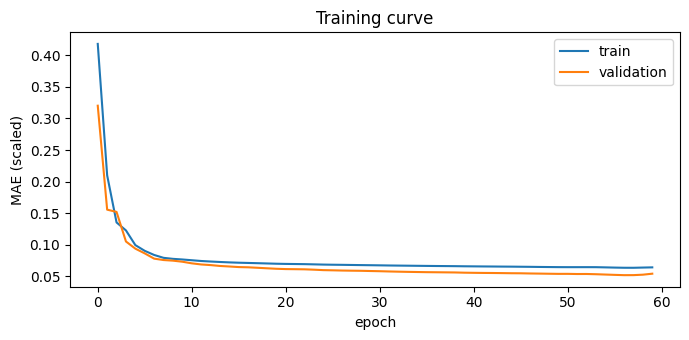

In [10]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,                   # upper limit; early stopping decides when to stop
    batch_size=BATCH,
    shuffle=False,
    callbacks=[early_stop],
    verbose=2,
)

plt.figure(figsize=(7, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MAE (scaled)"); plt.title("Training curve"); plt.legend()
plt.tight_layout(); plt.show()

### Step 9 — Evaluate the LSTM

We evaluate the trained LSTM on the 2017 validation set.

* Predict the next 24 hourly prices for each validation day.
* Convert predictions and actual values back to EUR/MWh using inverse_transform.
* Calculate MAE to measure the average prediction error.

Result: LSTM Validation MAE = 4.85 EUR/MWh.

This result will be compared with our seasonal naive baselines and the GRU model using the same validation period.

In [12]:
from sklearn.metrics import mean_absolute_error

# Predict validation prices
pred_scaled = model.predict(X_val)

# Convert predictions back to EUR/MWh
pred = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).reshape(pred_scaled.shape)

# Convert actual prices back to EUR/MWh
actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)

# Calculate MAE
lstm_mae = mean_absolute_error(actual.ravel(), pred.ravel())

print(f"LSTM Validation MAE: {lstm_mae:.2f} EUR/MWh")


rows = []

for T, values in zip(val_days, pred):
    for k, v in enumerate(values):
        rows.append((T, T + pd.Timedelta(hours=k), float(v)))

lstm_df = pd.DataFrame(
    rows,
    columns=["issue_time", "timestamp", "lstm"]
)

lstm_df.head()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
LSTM Validation MAE: 4.85 EUR/MWh


,issue_time,timestamp,lstm
0,2017-01-01 00:00:00+00:00,2017-01-01 00:00:00+00:00,59.896187
1,2017-01-01 00:00:00+00:00,2017-01-01 01:00:00+00:00,59.069408
2,2017-01-01 00:00:00+00:00,2017-01-01 02:00:00+00:00,55.847282
3,2017-01-01 00:00:00+00:00,2017-01-01 03:00:00+00:00,56.456707
4,2017-01-01 00:00:00+00:00,2017-01-01 04:00:00+00:00,57.215462


### Step 10 — Compare LSTM with Baselines

We compare the LSTM against three simple forecasting methods:

* Last Value: Repeats the last observed hourly price.
* Seasonal Naive (Lag 24): Uses prices from the same hours of the previous day.
* Seasonal Naive (Lag 168): Uses prices from the same hours of the previous week.

All methods are evaluated on the same 8,760 validation hours in 2017, using MAE in EUR/MWh.

Conclusion: LSTM achieved the lowest MAE, improving on the best seasonal naive baseline (Lag 24) by approximately 6.6%.

These results are based on validation data, not the final test set.

In [13]:
tgt_idx = lstm_df["timestamp"]
issue   = lstm_df["issue_time"]
comp = pd.DataFrame({
    "actual":     price.reindex(tgt_idx).values,
    "last_value": price.reindex(issue - pd.Timedelta(hours=1)).values,    # last known price at 00:00
    "lag_24":     price.reindex(tgt_idx - pd.Timedelta(hours=24)).values,
    "lag_168":    price.reindex(tgt_idx - pd.Timedelta(hours=168)).values,
    "lstm":       lstm_df["lstm"].values,
}).dropna()                                                               # same rows for every method

mae = {c: (comp["actual"] - comp[c]).abs().mean() for c in ["last_value", "lag_24", "lag_168", "lstm"]}
table = pd.DataFrame({"MAE (EUR/MWh)": mae}).round(2).sort_values("MAE (EUR/MWh)")
print("rows compared:", len(comp))
table

rows compared: 8760


,MAE (EUR/MWh)
lstm,4.85
lag_24,5.19
lag_168,6.27
last_value,7.56


#### Visual Comparison — Actual vs. LSTM vs. Lag 24

We visualize one week from the 2017 validation set (March 6–12) to compare:

* Actual: Real electricity prices.
* LSTM: Predictions from our trained model.
* Lag 24: Predictions using the same hours from the previous day.
Observation: LSTM follows several daily price patterns but overestimates prices during the sharp drop around March 12.

Conclusion: This week is only an illustrative example. Overall model performance is evaluated using MAE across the full 2017 validation period.

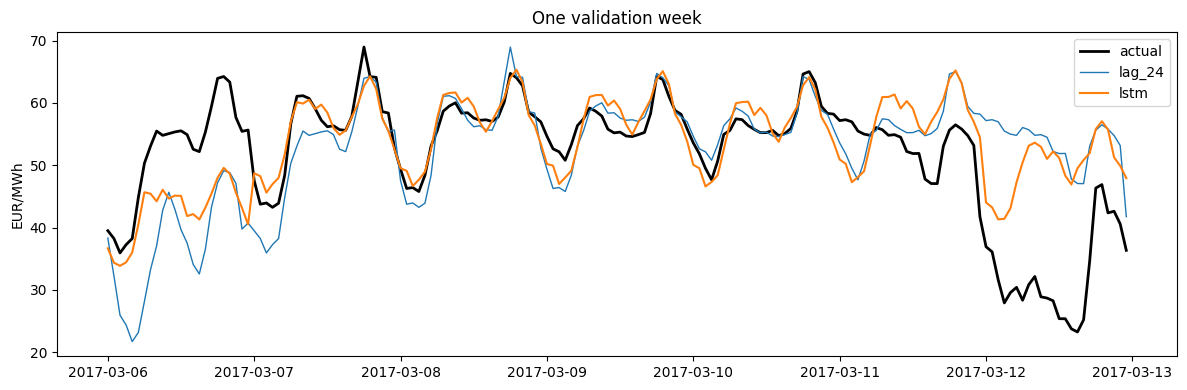

In [14]:
# one validation week: actual vs LSTM vs lag_24
week_start = utc("2017-03-06")
mask = (lstm_df["timestamp"] >= week_start) & (lstm_df["timestamp"] < week_start + pd.Timedelta(days=7))
w = lstm_df[mask].copy()
w["actual"] = price.reindex(w["timestamp"]).values
w["lag_24"] = price.reindex(w["timestamp"] - pd.Timedelta(hours=24)).values

plt.figure(figsize=(12, 4))
plt.plot(w["timestamp"], w["actual"], color="black", lw=2, label="actual")
plt.plot(w["timestamp"], w["lag_24"], lw=1, label="lag_24")
plt.plot(w["timestamp"], w["lstm"], lw=1.5, label="lstm")
plt.ylabel("EUR/MWh"); plt.title("One validation week"); plt.legend()
plt.tight_layout(); plt.show()

### Step 11 — Build and Train the GRU

We train a GRU model using the same settings as LSTM for a fair comparison.

* Input: Previous 168 hourly prices.
* GRU layer: 32 units.
* Output: Next 24 hourly prices.
* Optimizer: Adam.
* Loss: MAE.
* Early Stopping: Patience of 3, restoring the best weights.

Training stopped after 163 epochs.

The training and validation losses decreased throughout most of training, with no clear sustained divergence between the curves.

Next, we evaluate GRU using MAE in EUR/MWh and compare it with LSTM and the baselines.

Epoch 1/1000
23/23 - 5s - 231ms/step - loss: 0.4291 - val_loss: 0.3865
Epoch 2/1000
23/23 - 2s - 104ms/step - loss: 0.2471 - val_loss: 0.1334
Epoch 3/1000
23/23 - 3s - 112ms/step - loss: 0.1218 - val_loss: 0.1231
Epoch 4/1000
23/23 - 2s - 105ms/step - loss: 0.1070 - val_loss: 0.1002
Epoch 5/1000
23/23 - 3s - 121ms/step - loss: 0.0991 - val_loss: 0.0749
Epoch 6/1000
23/23 - 3s - 117ms/step - loss: 0.0882 - val_loss: 0.0715
Epoch 7/1000
23/23 - 3s - 113ms/step - loss: 0.0836 - val_loss: 0.0706
Epoch 8/1000
23/23 - 2s - 102ms/step - loss: 0.0810 - val_loss: 0.0688
Epoch 9/1000
23/23 - 2s - 99ms/step - loss: 0.0781 - val_loss: 0.0669
Epoch 10/1000
23/23 - 3s - 121ms/step - loss: 0.0752 - val_loss: 0.0645
Epoch 11/1000
23/23 - 2s - 101ms/step - loss: 0.0726 - val_loss: 0.0626
Epoch 12/1000
23/23 - 2s - 105ms/step - loss: 0.0708 - val_loss: 0.0608
Epoch 13/1000
23/23 - 2s - 103ms/step - loss: 0.0692 - val_loss: 0.0596
Epoch 14/1000
23/23 - 2s - 96ms/step - loss: 0.0682 - val_loss: 0.0587
Epo

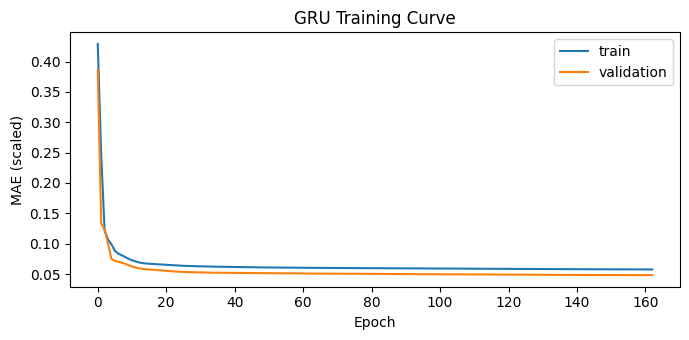

In [16]:
keras.utils.set_random_seed(SEED)

gru_model = keras.Sequential([
    keras.Input(shape=(INPUT_WINDOW, 1)),
    keras.layers.GRU(UNITS),          # the only change compared with the LSTM model
    keras.layers.Dense(H),            # 24 outputs = next 24 hours
])
gru_model.compile(optimizer="adam", loss="mae")

gru_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True,
)

gru_history = gru_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,                        # upper limit; early stopping decides when to stop
    batch_size=BATCH,
    shuffle=False,
    callbacks=[gru_early_stop],
    verbose=2,
)

plt.figure(figsize=(7, 3.5))
plt.plot(gru_history.history["loss"], label="train")
plt.plot(gru_history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("MAE (scaled)")
plt.title("GRU Training Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Predict GRU prices on validation data
gru_scaled = gru_model.predict(X_val)

# Convert predictions back to EUR/MWh
gru_pred = scaler.inverse_transform(
    gru_scaled.reshape(-1, 1)
).reshape(gru_scaled.shape)

# Calculate validation MAE
gru_mae = mean_absolute_error(actual.ravel(), gru_pred.ravel())

print(f"GRU Validation MAE: {gru_mae:.2f} EUR/MWh")

# Create a table of GRU predictions
rows = []

for T, values in zip(val_days, gru_pred):
    for k, v in enumerate(values):
        rows.append((T, T + pd.Timedelta(hours=k), float(v)))

gru_df = pd.DataFrame(
    rows,
    columns=["issue_time", "timestamp", "gru"]
)

gru_df.head()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
GRU Validation MAE: 4.50 EUR/MWh


,issue_time,timestamp,gru
0,2017-01-01 00:00:00+00:00,2017-01-01 00:00:00+00:00,62.202499
1,2017-01-01 00:00:00+00:00,2017-01-01 01:00:00+00:00,61.274048
2,2017-01-01 00:00:00+00:00,2017-01-01 02:00:00+00:00,59.118465
3,2017-01-01 00:00:00+00:00,2017-01-01 03:00:00+00:00,60.259697
4,2017-01-01 00:00:00+00:00,2017-01-01 04:00:00+00:00,61.541035


### Step 12 — Model Comparison

We compare LSTM, GRU, and three baseline methods on the same 8,760 validation hours in 2017.

* MAE: Our primary evaluation metric, measuring average absolute prediction error.
* RMSE: A secondary metric that gives more weight to large errors.

Observation: GRU achieved the lowest MAE and RMSE, reducing MAE by approximately 13.3% compared with the best baseline (Lag 24). LSTM also outperformed all baseline methods.

These are validation results from the initial models. We will test improvements before selecting the final model and evaluating it on the untouched 2018 test set.

In [19]:
# one table with every method on exactly the same rows
all_df = lstm_df.merge(gru_df, on=["issue_time", "timestamp"], how="inner")
t_idx, i_idx = all_df["timestamp"], all_df["issue_time"]

cmp_all = pd.DataFrame({
    "actual":     price.reindex(t_idx).values,
    "last_value": price.reindex(i_idx - pd.Timedelta(hours=1)).values,     # last known price at 00:00
    "lag_24":     price.reindex(t_idx - pd.Timedelta(hours=24)).values,    # same hour yesterday
    "lag_168":    price.reindex(t_idx - pd.Timedelta(hours=168)).values,   # same hour last week
    "lstm":       all_df["lstm"].values,
    "gru":        all_df["gru"].values,
}).dropna()

METHODS = ["last_value", "lag_24", "lag_168", "lstm", "gru"]
scores = {}
for m in METHODS:
    err = cmp_all["actual"] - cmp_all[m]
    scores[m] = {"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean())}

final_table = pd.DataFrame(scores).T.round(2).sort_values("MAE")
final_table["MAE vs lag_24 (%)"] = ((1 - final_table["MAE"] / final_table.loc["lag_24", "MAE"]) * 100).round(1)
print("rows compared:", len(cmp_all))
final_table

rows compared: 8760


,MAE,RMSE,MAE vs lag_24 (%)
gru,4.50,6.24,13.3
lstm,4.85,6.54,6.6
lag_24,5.19,7.49,0.0
lag_168,6.27,8.88,-20.8
last_value,7.56,9.79,-45.7


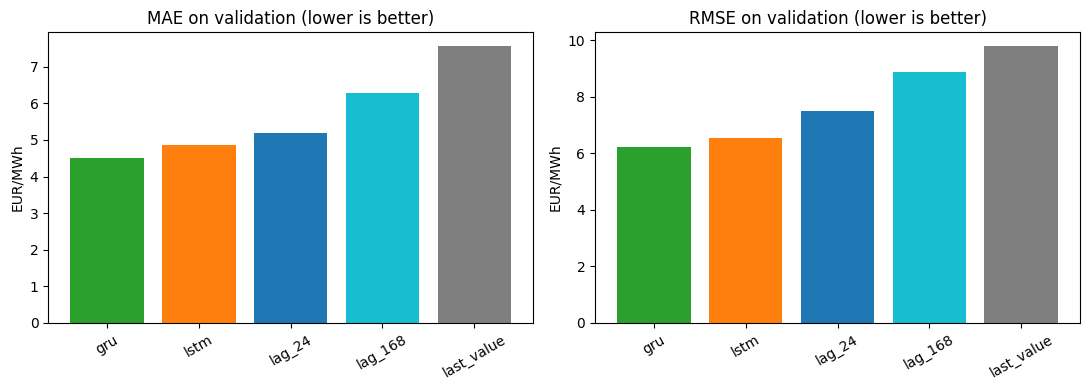

In [20]:
# bar chart: MAE and RMSE for every method
colors = {"last_value": "tab:gray", "lag_24": "tab:blue", "lag_168": "tab:cyan",
          "lstm": "tab:orange", "gru": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    vals = final_table[metric]
    ax.bar(vals.index, vals.values, color=[colors[m] for m in vals.index])
    ax.set_ylabel("EUR/MWh"); ax.set_title(f"{metric} on validation (lower is better)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

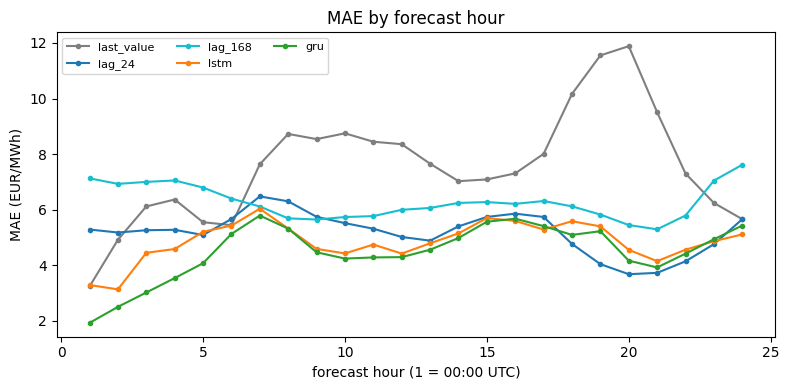

In [21]:
# MAE by forecast hour (1..24): who is better early or late in the day?
step = cmp_all.assign(step=np.tile(np.arange(1, H + 1), len(cmp_all) // H))
fig, ax = plt.subplots(figsize=(8, 4))
for m in METHODS:
    e = (step["actual"] - step[m]).abs().groupby(step["step"]).mean()
    ax.plot(e.index, e.values, marker="o", ms=3, label=m, color=colors[m])
ax.set_xlabel("forecast hour (1 = 00:00 UTC)"); ax.set_ylabel("MAE (EUR/MWh)")
ax.set_title("MAE by forecast hour"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

### Visual Comparison — One Validation Week

We compare actual electricity prices with Lag-24, LSTM, and GRU predictions for March 6–12, 2017.

Both deep learning models follow many daily price fluctuations. However, neither captures the sharp price drop around March 12 accurately.

This is an illustrative example of forecasting errors. Our overall model comparison is based on the full 2017 validation period.

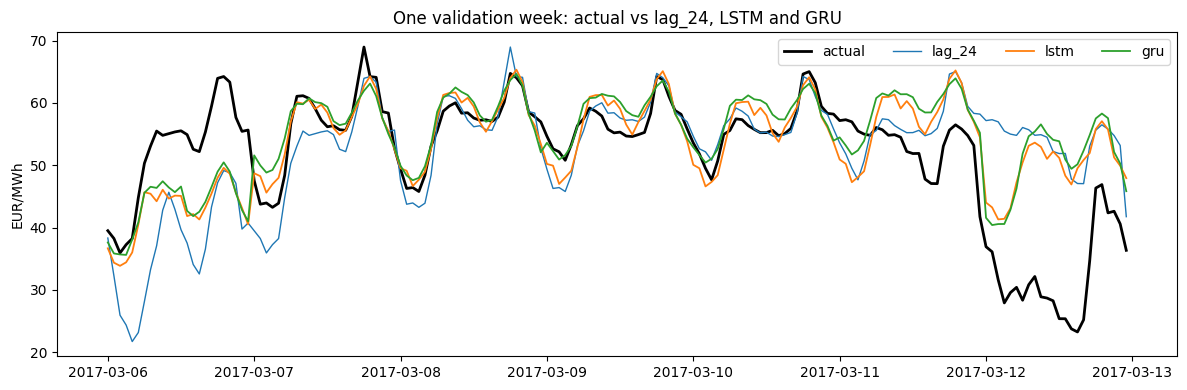

In [22]:
# one validation week: actual vs all methods
wk = all_df.copy()
wk["actual"]  = price.reindex(wk["timestamp"]).values
wk["lag_24"]  = price.reindex(wk["timestamp"] - pd.Timedelta(hours=24)).values
wk = wk[(wk["timestamp"] >= week_start) & (wk["timestamp"] < week_start + pd.Timedelta(days=7))]

plt.figure(figsize=(12, 4))
plt.plot(wk["timestamp"], wk["actual"], color="black", lw=2, label="actual")
plt.plot(wk["timestamp"], wk["lag_24"], lw=1, color=colors["lag_24"], label="lag_24")
plt.plot(wk["timestamp"], wk["lstm"],   lw=1.3, color=colors["lstm"], label="lstm")
plt.plot(wk["timestamp"], wk["gru"],    lw=1.3, color=colors["gru"],  label="gru")
plt.ylabel("EUR/MWh"); plt.title("One validation week: actual vs lag_24, LSTM and GRU"); plt.legend(ncol=4)
plt.tight_layout(); plt.show()

### Step 13 — Window Creation Improvement
We explored two window creation strategies:

* Daily windows: One training window every 24 hours.
* Hourly sliding windows: One training window every hour.

Both strategies use 168 hours of historical prices to predict the next 24 hours.

The goal is to increase the number of training examples without changing the original dataset or using future information.

We will train LSTM and GRU using the hourly sliding windows and compare their validation MAE with the original daily-window models.

The validation dates and forecast horizon will remain unchanged.

In [24]:
# Hourly sliding window positions
train_hours = pd.date_range(
    start=train_days[0],
    end=utc(TRAIN_END),
    freq="h"
)

print("Hourly windows:", len(train_hours))
print("First:", train_hours[0])
print("Last:", train_hours[-1])

assert train_hours[-1] + pd.Timedelta(hours=H-1) <= utc(TRAIN_END) + pd.Timedelta(hours=23)

Hourly windows: 17353
First: 2015-01-08 00:00:00+00:00
Last: 2016-12-31 00:00:00+00:00


In [25]:
# Create hourly training windows
X_train_hourly, y_train_hourly = make_windows(scaled, train_hours)

print("X_train_hourly:", X_train_hourly.shape)
print("y_train_hourly:", y_train_hourly.shape)

# Verify input and target dimensions
assert X_train_hourly.shape == (len(train_hours), INPUT_WINDOW, 1)
assert y_train_hourly.shape == (len(train_hours), H)

X_train_hourly: (17353, 168, 1)
y_train_hourly: (17353, 24)


In [26]:
# Check the first and last hourly training windows
for T in [train_hours[0], train_hours[-1]]:
    input_start = T - pd.Timedelta(hours=INPUT_WINDOW)
    input_end = T - pd.Timedelta(hours=1)
    target_end = T + pd.Timedelta(hours=H-1)

    print("Forecast time:", T)
    print("Input:", input_start, "to", input_end)
    print("Target:", T, "to", target_end)
    print()

    assert input_end < T
    assert target_end <= utc(TRAIN_END) + pd.Timedelta(hours=23)

Forecast time: 2015-01-08 00:00:00+00:00
Input: 2015-01-01 00:00:00+00:00 to 2015-01-07 23:00:00+00:00
Target: 2015-01-08 00:00:00+00:00 to 2015-01-08 23:00:00+00:00

Forecast time: 2016-12-31 00:00:00+00:00
Input: 2016-12-24 00:00:00+00:00 to 2016-12-30 23:00:00+00:00
Target: 2016-12-31 00:00:00+00:00 to 2016-12-31 23:00:00+00:00



In [27]:
# LSTM with hourly training windows
keras.utils.set_random_seed(SEED)

lstm_hourly = keras.Sequential([
    keras.Input(shape=(INPUT_WINDOW, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(H)
])

lstm_hourly.compile(
    optimizer="adam",
    loss="mae"
)

lstm_hourly.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
lstm_hourly_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

lstm_hourly_history = lstm_hourly.fit(
    X_train_hourly, y_train_hourly,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=BATCH,
    shuffle=False,
    callbacks=[lstm_hourly_stop],
    verbose=2
)

Epoch 1/1000
543/543 - 35s - 64ms/step - loss: 0.1060 - val_loss: 0.1108
Epoch 2/1000
543/543 - 27s - 50ms/step - loss: 0.0799 - val_loss: 0.0950
Epoch 3/1000
543/543 - 28s - 51ms/step - loss: 0.0729 - val_loss: 0.0905
Epoch 4/1000
543/543 - 30s - 56ms/step - loss: 0.0685 - val_loss: 0.0864
Epoch 5/1000
543/543 - 30s - 55ms/step - loss: 0.0624 - val_loss: 0.0806
Epoch 6/1000
543/543 - 31s - 56ms/step - loss: 0.0599 - val_loss: 0.0785
Epoch 7/1000
543/543 - 30s - 55ms/step - loss: 0.0587 - val_loss: 0.0767
Epoch 8/1000
543/543 - 32s - 59ms/step - loss: 0.0579 - val_loss: 0.0767
Epoch 9/1000
543/543 - 29s - 53ms/step - loss: 0.0573 - val_loss: 0.0768
Epoch 10/1000
543/543 - 30s - 56ms/step - loss: 0.0569 - val_loss: 0.0773


In [29]:
# Evaluate LSTM with hourly training windows
hourly_scaled = lstm_hourly.predict(X_val, verbose=0)

hourly_pred = scaler.inverse_transform(
    hourly_scaled.reshape(-1, 1)
).reshape(hourly_scaled.shape)

lstm_hourly_mae = mean_absolute_error(
    actual.ravel(),
    hourly_pred.ravel()
)

print(f"Original LSTM MAE: {lstm_mae:.2f} EUR/MWh")
print(f"Hourly-window LSTM MAE: {lstm_hourly_mae:.2f} EUR/MWh")

Original LSTM MAE: 4.85 EUR/MWh
Hourly-window LSTM MAE: 7.15 EUR/MWh


### Hourly Sliding Windows — LSTM Results

We tested whether increasing training windows from 724 daily windows to 17,353 hourly sliding windows would improve LSTM performance.

Training Strategy	Validation MAE (EUR/MWh)
Daily windows	4.85
Hourly sliding windows	7.15

Result: Hourly sliding windows increased the validation error.

Possible explanation: Hourly windows include forecasts starting at different times of day, while our validation forecasts are issued daily at 00:00 UTC. The model does not explicitly receive the forecast issue hour as a feature. The overlapping training windows and increased number of weight updates may also affect training.

Decision: Keep daily training windows for now. We will prioritize other improvements before final model selection.